# Rent and inflation across three cities

Jiahui Zhang | Independent applied economics project

## Summary

Rent growth trailed local headline CPI in all three cities in the year to September 2026. Sydney had the fastest annual rent growth (**3.48%**), followed by Melbourne (**2.47%**) and Canberra (**1.40%**). Over the full monthly window from April 2024, rent growth exceeded local CPI in Melbourne and Sydney and fell **5.56 percentage points** short in Canberra.

## Context and methods

Compare how quickly rents and all consumer prices changed within each city, then compare the rent growth paths across cities. Use published original index levels, rebase them to 100 at the first comparable month for the trend chart, and calculate growth as 100 × (end / start − 1). Growth gaps are rent growth minus local CPI growth in percentage points.

### Key assumptions

- Monthly comparisons use April 2024 to September 2026, the complete overlap of headline CPI and rents for all three cities. The annual trend begins in April 2025 because it uses a 12-month lag.
- Historical comparisons use a separate quarterly release. Quarter labels name the last month of each quarter. The December 2019 and September 2022 starting points test how the historical comparison changes with the chosen window.
- The rent index measures price changes for rents paid by new and existing tenants. Comparing index growth across cities does not provide their weekly rents in dollars or their rent-to-income ratios. Headline CPI includes rents.

## Data

[ABS September 2026 monthly CPI release](https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-index-australia/sep-2026#data-downloads), Tables 1 and 10. [ABS September quarter 2025 CPI release](https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-index-australia/sep-quarter-2025#data-downloads), Table 9. The files are retained under `data/raw/`. The loader verifies exact series IDs, descriptions, frequency and full coverage. It also reconciles all three monthly headline series against Table 1.

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
from analysis import CASE_CITIES, growth_table, load_panels
from figures import plot_city, plot_historical, plot_rent_yoy

monthly, quarterly = load_panels()
for name, panel in [("Monthly", monthly), ("Quarterly", quarterly)]:
    print(f"{name}: {len(panel)} periods, {panel.shape[1]} series, "
          f"{panel.index[0]:%b %Y} to {panel.index[-1]:%b %Y}, "
          f"{panel.isna().sum().sum()} missing values")

Monthly: 30 periods, 6 series, Apr 2024 to Sep 2026, 0 missing values
Quarterly: 24 periods, 6 series, Dec 2019 to Sep 2025, 0 missing values


## City cases

All charts use the same scale. Both series start at 100 in April 2024, so their separation represents a difference in cumulative percentage growth.

### Canberra | Widest gap below local inflation

Annual rent inflation went from 0.65% to 1.40% between September 2025 and September 2026. Since April 2024, rents rose 2.38% and local CPI rose 7.94%. Rent growth lagged local CPI over both the latest year and the full monthly window. In the latest year, local headline CPI rose **4.65%**, leaving a rent-minus-CPI gap of **-3.25 percentage points**.

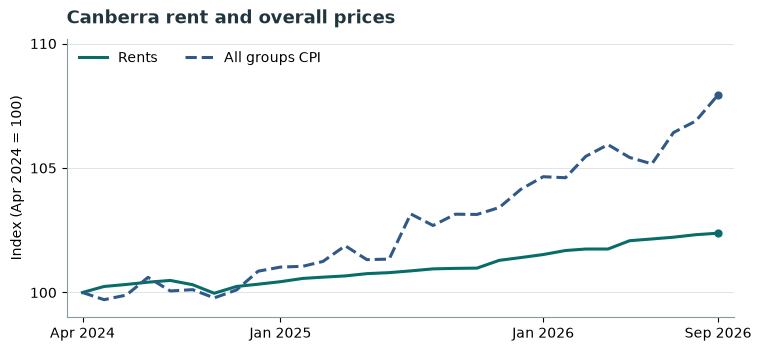

In [2]:
fig = plot_city(monthly, 'Canberra')
display(fig)
plt.close(fig)

### Melbourne | Rent inflation slowed

Annual rent inflation went from 3.62% to 2.47% between September 2025 and September 2026. Since April 2024, rents rose 9.13% and local CPI rose 7.77%. Rents outpaced CPI over the full monthly window, even as annual rent inflation cooled. In the latest year, local headline CPI rose **4.01%**, leaving a rent-minus-CPI gap of **-1.54 percentage points**.

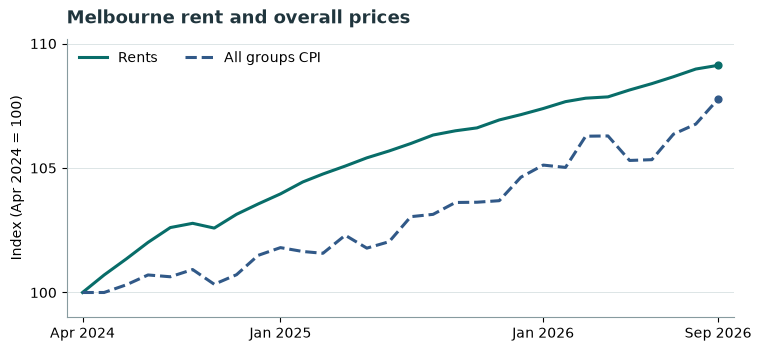

In [3]:
fig = plot_city(monthly, 'Melbourne')
display(fig)
plt.close(fig)

### Sydney | Fastest rent growth in the latest year

Annual rent inflation went from 3.22% to 3.48% between September 2025 and September 2026. Since April 2024, rents rose 9.64% and local CPI rose 7.88%. Sydney also posted the largest cumulative rent increase since April 2024. In the latest year, local headline CPI rose **4.31%**, leaving a rent-minus-CPI gap of **-0.83 percentage points**.

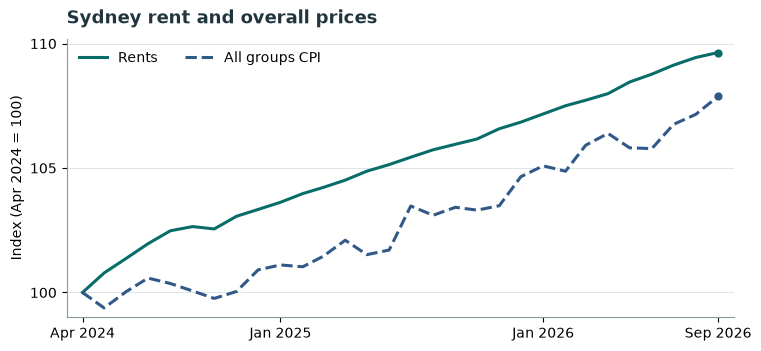

In [4]:
fig = plot_city(monthly, 'Sydney')
display(fig)
plt.close(fig)

## Cross-city comparison

The lines compare each month's rent index with the same month one year earlier. The two tables use the same ending month and different starting months; this makes it possible to compare short-term inflation with the cumulative path.

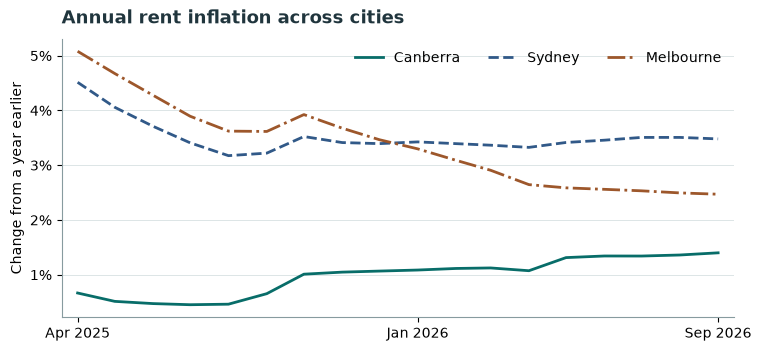

Measure,Rents,All groups CPI,Rent minus CPI (pp)
City,,,
Canberra,+1.40,+4.65,-3.25
Melbourne,+2.47,+4.01,-1.54
Sydney,+3.48,+4.31,-0.83


Measure,Rents,All groups CPI,Rent minus CPI (pp)
City,,,
Canberra,+2.38,+7.94,-5.56
Melbourne,+9.13,+7.77,+1.36
Sydney,+9.64,+7.88,+1.76


In [5]:
fig = plot_rent_yoy(monthly)
display(fig)
plt.close(fig)
for label, start in [("Year to September 2026", "2025-09-01"),
                     ("April 2024 to September 2026", "2024-04-01")]:
    table = growth_table(monthly, start, "2026-09-01").loc[list(CASE_CITIES)]
    display(table.style.set_caption(label).format("{:+.2f}"))

### The historical answer depends on the starting quarter

From December 2019 to September 2025, rents lagged local CPI in all three cities. Moving the start to September 2022 reverses the sign for Sydney and Melbourne. The starting quarter changes which part of the rental cycle is included. ABS also introduced a new rent data source in July 2022, so the long comparison spans a collection change.

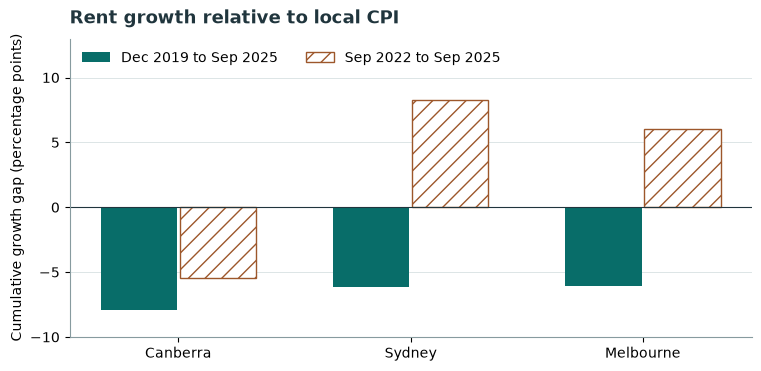

Measure,Rents,All groups CPI,Rent minus CPI (pp)
City,,,
Canberra,+4.80,+10.23,-5.43
Sydney,+20.16,+11.90,+8.26
Melbourne,+16.84,+10.78,+6.07


In [6]:
fig = plot_historical(quarterly)
display(fig)
plt.close(fig)
display(growth_table(quarterly, "2022-09-01", "2025-09-01").style.format("{:+.2f}"))

## Takeaways

Canberra rents rose but lagged broader inflation over both monthly windows. Sydney and Melbourne show how the choice of starting point can change the comparison. These are descriptive comparisons of published price indexes; an affordability study would need weekly rent and household income data.